# Cat and Dog Image Classifier

**Author: cear12**

A solution to the [freeCodeCamp project](https://www.freecodecamp.org/learn/machine-learning-with-python/machine-learning-with-python-projects/cat-and-dog-image-classifier).
The goal is to classify at least **63%** of the 50 test photographs correctly.
This notebook runs independently in Jupyter or Google Colab: run the cells from top to bottom.
In Colab, TensorFlow is already available. Locally, install `requirements.txt` with Python 3.12.

The convolutional network is trained from scratch. Only training images receive random
transformations; validation images select the best checkpoint. Test labels appear only
in the final evaluation and never take part in training or checkpoint selection.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import hashlib
import json
import math
import urllib.error
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential, layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
tf.keras.utils.set_random_seed(SEED)
# Limit CPU oversubscription on laptops; GPU execution is unaffected.
tf.config.threading.set_intra_op_parallelism_threads(min(8, os.cpu_count() or 1))
tf.config.threading.set_inter_op_parallelism_threads(2)
print(f"TensorFlow {tf.__version__}; seed {SEED}")

TensorFlow 2.20.0; seed 42


## 1–2. Load the official dataset

The archive contains 2,000 training images, 1,000 validation images and 50 unlabeled
test images. The original CDN and the official GitHub mirror contain the same archive;
its SHA-256 checksum is checked before extraction. Metadata files from macOS are skipped.
Downloads and extraction are cached, so rerunning the notebook does not download data again.

In [2]:
DATA_URLS = (
    "https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip",
    "https://raw.githubusercontent.com/freeCodeCamp/cdn/main/build/project-data/cats-and-dogs/cats_and_dogs.zip",
)
DATA_SHA256 = "fbbd17588a5d51816c32ffe7c1b61cd465f4c80782430d3f736d7a58db12f933"


def file_sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def extract_images(archive_path, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for entry in archive.infolist():
            relative = Path(entry.filename)
            if not relative.parts or relative.parts[0] != "cats_and_dogs":
                continue
            if relative.suffix.lower() != ".jpg" or relative.name.startswith("."):
                continue
            target = (destination / relative).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("Archive contains a path outside the data directory")
            archive.extract(entry, destination)


def prepare_data(destination="."):
    destination = Path(destination)
    cache = destination / ".cache"
    cache.mkdir(parents=True, exist_ok=True)
    archive_path = cache / "cats_and_dogs.zip"
    if not archive_path.exists() or file_sha256(archive_path) != DATA_SHA256:
        errors = []
        for url in DATA_URLS:
            temporary = archive_path.with_suffix(".download")
            try:
                request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(request, timeout=120) as response, temporary.open("wb") as out:
                    import shutil
                    shutil.copyfileobj(response, out)
                if file_sha256(temporary) != DATA_SHA256:
                    raise ValueError("Dataset checksum does not match the official archive")
                temporary.replace(archive_path)
                break
            except (OSError, ValueError) as error:
                temporary.unlink(missing_ok=True)
                errors.append(f"{url}: {error}")
        else:
            raise RuntimeError("Could not download the dataset:\n" + "\n".join(errors))

    root = destination / "cats_and_dogs"
    expected = {"train/cats": 1000, "train/dogs": 1000,
                "validation/cats": 500, "validation/dogs": 500, "test": 50}
    if any(len(list((root / folder).glob("*.jpg"))) != count for folder, count in expected.items()):
        extract_images(archive_path, destination)
    for folder, count in expected.items():
        found = len(list((root / folder).glob("*.jpg")))
        if found != count:
            raise ValueError(f"{folder}: expected {count} images, found {found}")
    return root

In [3]:
PATH = prepare_data()
train_dir = PATH / "train"
validation_dir = PATH / "validation"
test_dir = PATH / "test"
total_train = len(list(train_dir.glob("*/*.jpg")))
total_val = len(list(validation_dir.glob("*/*.jpg")))
total_test = len(list(test_dir.glob("*.jpg")))

batch_size = 32
epochs = 25
IMG_HEIGHT = 150
IMG_WIDTH = 150
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
print(f"Training: {total_train}; validation: {total_val}; test: {total_test}")

Training: 2000; validation: 1000; test: 50


## 3. Image generators

All images are resized to 150 × 150 and rescaled from `[0, 255]` to `[0, 1]`.
Explicit class order gives **cat = 0**, **dog = 1**. Validation and test iterators
do not shuffle. The flat `test/` folder is loaded as one directory with no labels.

In [4]:
def make_generators(root, image_size=(150, 150), batch_size=32, augment=False):
    options = dict(rescale=1.0 / 255)
    if augment:
        options.update(rotation_range=20, width_shift_range=0.1,
                       height_shift_range=0.1, zoom_range=0.15,
                       horizontal_flip=True, fill_mode="nearest")
    train_image_generator = ImageDataGenerator(**options)
    validation_image_generator = ImageDataGenerator(rescale=1.0 / 255)
    test_image_generator = ImageDataGenerator(rescale=1.0 / 255)

    train_data_gen = train_image_generator.flow_from_directory(
        str(Path(root) / "train"), classes=["cats", "dogs"],
        target_size=image_size, batch_size=batch_size,
        class_mode="binary", shuffle=True, seed=SEED)
    val_data_gen = validation_image_generator.flow_from_directory(
        str(Path(root) / "validation"), classes=["cats", "dogs"],
        target_size=image_size, batch_size=batch_size,
        class_mode="binary", shuffle=False)
    test_data_gen = test_image_generator.flow_from_directory(
        str(root), classes=["test"], target_size=image_size,
        batch_size=batch_size, class_mode=None, shuffle=False)

    # Keras 3 reads worker settings from the iterator itself.
    train_data_gen.workers = 4
    train_data_gen.max_queue_size = 8
    return (train_image_generator, validation_image_generator, test_image_generator,
            train_data_gen, val_data_gen, test_data_gen)

In [5]:
(train_image_generator, validation_image_generator, test_image_generator,
 train_data_gen, val_data_gen, test_data_gen) = make_generators(
    PATH, (IMG_HEIGHT, IMG_WIDTH), batch_size)
assert train_data_gen.class_indices == val_data_gen.class_indices == {"cats": 0, "dogs": 1}
assert test_data_gen.samples == total_test
print("Class mapping:", train_data_gen.class_indices)
print("Test filenames (lexicographic):", test_data_gen.filenames[:12])

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 50 images belonging to 1 classes.


Class mapping: {'cats': 0, 'dogs': 1}
Test filenames (lexicographic): ['test\\1.jpg', 'test\\10.jpg', 'test\\11.jpg', 'test\\12.jpg', 'test\\13.jpg', 'test\\14.jpg', 'test\\15.jpg', 'test\\16.jpg', 'test\\17.jpg', 'test\\18.jpg', 'test\\19.jpg', 'test\\2.jpg']


## 4. Inspect the training images

`plotImages` accepts either images alone or a dog probability for each image.
A probability greater than 0.5 means dog; otherwise the label is cat.

In [6]:
def plotImages(images_arr, probabilities=False, *, columns=5, save_path=None):
    images = np.asarray(images_arr)
    if len(images) == 0:
        raise ValueError("At least one image is required")
    values = None if probabilities is False or probabilities is None else np.asarray(probabilities).reshape(-1)
    if values is not None and len(values) != len(images):
        raise ValueError("Each image needs exactly one probability")
    columns = min(columns, len(images))
    rows = math.ceil(len(images) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3 * rows), squeeze=False)
    for index, ax in enumerate(axes.flat):
        ax.axis("off")
        if index >= len(images):
            continue
        ax.imshow(images[index])
        if values is not None:
            probability = float(values[index])
            label = "dog" if probability > 0.5 else "cat"
            confidence = probability if probability > 0.5 else 1.0 - probability
            ax.set_title(f"{confidence:.1%} {label}")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=110, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return fig

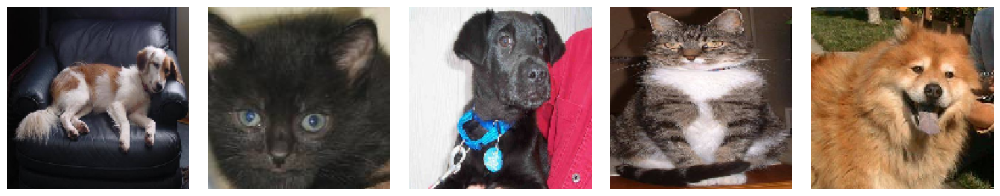

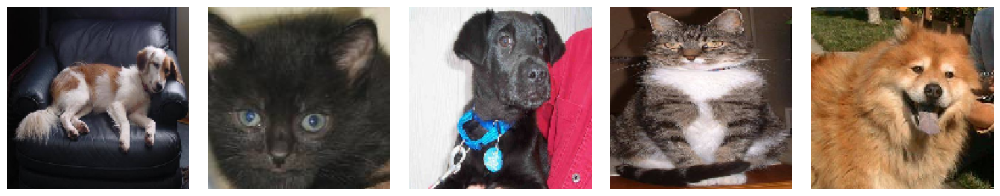

In [7]:
sample_training_images, _ = train_data_gen[0]
plotImages(sample_training_images[:5], save_path=ARTIFACTS / "training_samples.png")

## 5–6. Augment training images

Small rotations, shifts, zooms and horizontal flips add variety without changing the
labels. The five examples below transform the **same** source image, making their
effect visible. Validation and test images still receive only resizing and rescaling.

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 50 images belonging to 1 classes.


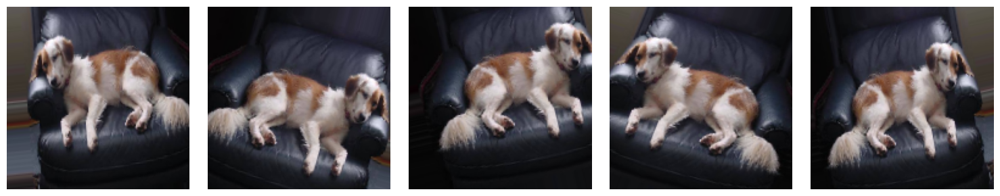

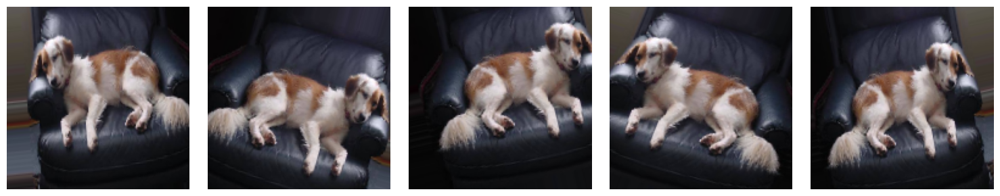

In [8]:
(train_image_generator, validation_image_generator, test_image_generator,
 train_data_gen, val_data_gen, test_data_gen) = make_generators(
    PATH, (IMG_HEIGHT, IMG_WIDTH), batch_size, augment=True)

augmented_images = [train_image_generator.random_transform(
    sample_training_images[0], seed=SEED + i) for i in range(5)]
plotImages(augmented_images, save_path=ARTIFACTS / "augmentation.png")

## 7. Build and compile the network

Four `Conv2D` / `MaxPooling2D` blocks learn increasingly complex image features.
`Flatten` and a dense layer perform classification; dropout limits overfitting.
A single sigmoid output estimates the dog probability. Binary cross-entropy matches
the two-class labels. No pretrained weights or test labels are used.

In [9]:
def build_model(image_shape=(150, 150, 3)):
    model = Sequential([
        layers.Input(shape=image_shape),
        layers.Conv2D(16, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name="cat_dog_classifier")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

In [10]:
model = build_model((IMG_HEIGHT, IMG_WIDTH, 3))
model.summary()

Model: "cat_dog_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,327,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,424,801 (5.44 MB)

 Trainable params: 1,424,801 (5.44 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train using the validation split

Each epoch visits every training batch, including the last partial batch. Early stopping
restores the lowest validation-loss weights; the learning rate decreases when validation
loss stalls. Consequently, the actual number of epochs may be smaller than the maximum.
The checkpoint is selected exclusively using validation loss.

In [11]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(ARTIFACTS / "cat_dog_classifier.keras"),
        monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    tf.keras.callbacks.CSVLogger(str(ARTIFACTS / "training.csv")),
]
history = model.fit(train_data_gen, epochs=epochs, validation_data=val_data_gen,
                    callbacks=callbacks, verbose=2)
# Reload the same best checkpoint used for the final test and later inference.
model = tf.keras.models.load_model(ARTIFACTS / "cat_dog_classifier.keras")

Epoch 1/25


63/63 - 12s - 188ms/step - accuracy: 0.5230 - loss: 0.6939 - val_accuracy: 0.6050 - val_loss: 0.6898 - learning_rate: 0.0010


Epoch 2/25


63/63 - 5s - 79ms/step - accuracy: 0.5730 - loss: 0.6828 - val_accuracy: 0.6220 - val_loss: 0.6529 - learning_rate: 0.0010


Epoch 3/25


63/63 - 5s - 72ms/step - accuracy: 0.5890 - loss: 0.6621 - val_accuracy: 0.5530 - val_loss: 0.6561 - learning_rate: 0.0010


... (40 outputs left out)

Epoch 24/25


63/63 - 5s - 81ms/step - accuracy: 0.7965 - loss: 0.4489 - val_accuracy: 0.7660 - val_loss: 0.4638 - learning_rate: 5.0000e-04


Epoch 25/25


63/63 - 5s - 81ms/step - accuracy: 0.7970 - loss: 0.4412 - val_accuracy: 0.7730 - val_loss: 0.4704 - learning_rate: 5.0000e-04


## 9. Plot accuracy and loss

These curves use the actual training history, including any early stop.

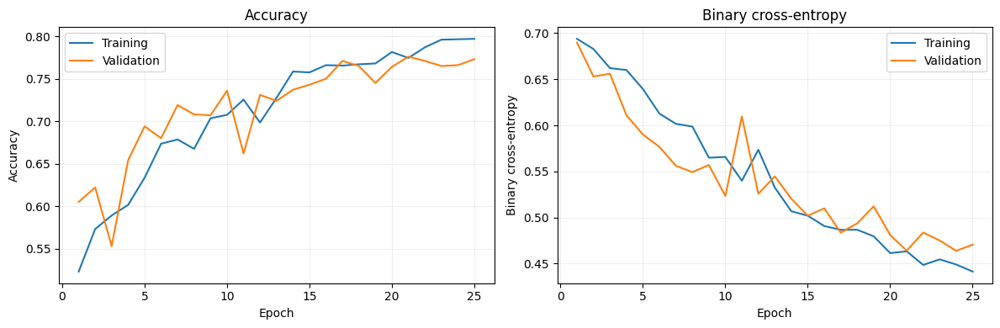

Best epoch: 24; validation accuracy: 76.6%


In [12]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, training, validation, title in zip(
    axes, (acc, loss), (val_acc, val_loss), ("Accuracy", "Binary cross-entropy")):
    ax.plot(epochs_range, training, label="Training")
    ax.plot(epochs_range, validation, label="Validation")
    ax.set(xlabel="Epoch", ylabel=title, title=title)
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS / "training_history.png", dpi=140)
plt.show()
plt.close(fig)

val_data_gen.reset()
validation_loss, validation_accuracy = model.evaluate(val_data_gen, verbose=0)
best_epoch = int(np.argmin(val_loss)) + 1
print(f"Best epoch: {best_epoch}; validation accuracy: {validation_accuracy:.1%}")

## 10. Predict all 50 test images

`shuffle=False` preserves the iterator's **lexicographic** filename order
(`1.jpg`, `10.jpg`, …, `2.jpg`, …), which matches the supplied answer list.
Predictions consume the full iterator, including the final partial batch.
The displayed confidence is the model's sigmoid score, not a calibrated certainty.

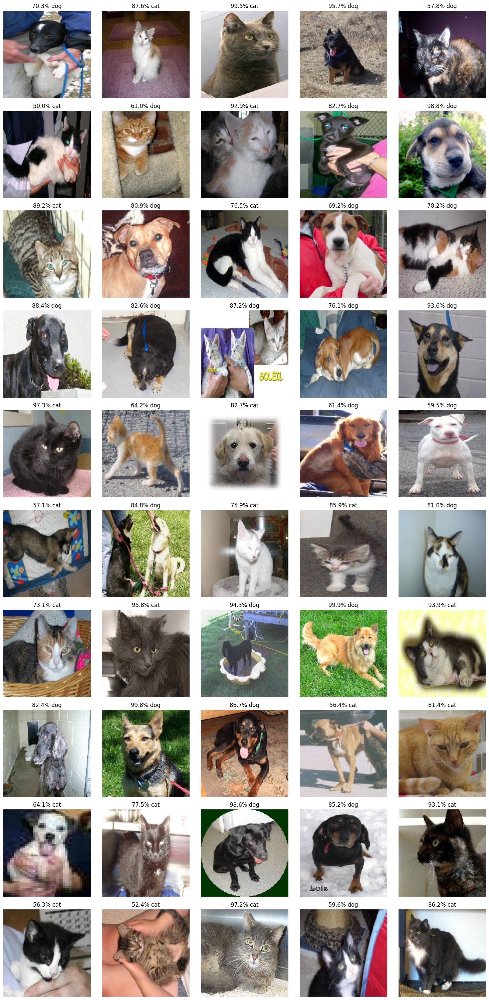

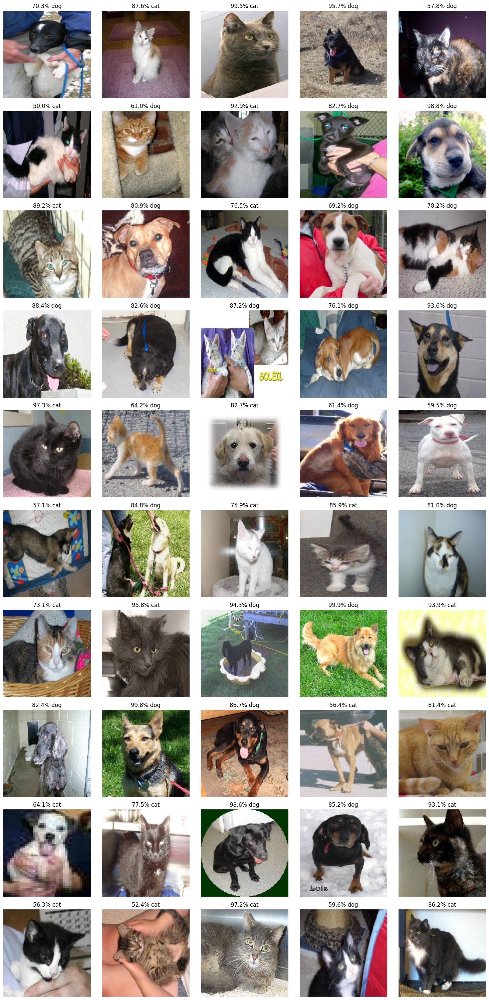

In [13]:
test_data_gen.reset()
probabilities = model.predict(test_data_gen, verbose=0).reshape(-1)
test_images = np.concatenate([test_data_gen[i] for i in range(len(test_data_gen))])
assert len(probabilities) == len(test_images) == total_test == 50
assert test_data_gen.filenames == sorted(test_data_gen.filenames)
plotImages(test_images, probabilities, save_path=ARTIFACTS / "test_predictions.png")

## 11. Evaluate against the supplied answers

The answer list below is the unchanged freeCodeCamp answer list. It is used only now,
after training and validation-based checkpoint selection are complete.

In [14]:
def score_predictions(probabilities, answers):
    values = np.asarray(probabilities, dtype=float).reshape(-1)
    labels = np.asarray(answers)
    if labels.ndim != 1 or len(values) != len(labels) or len(values) == 0:
        raise ValueError("Predictions and answers must be nonempty and have matching lengths")
    if not np.all(np.isfinite(values)) or np.any((values < 0) | (values > 1)):
        raise ValueError("Probabilities must be finite values between zero and one")
    if not np.all(np.isin(labels, [0, 1])):
        raise ValueError("Answers must contain only 0 (cat) and 1 (dog)")
    predicted = (values > 0.5).astype(int)
    correct = int(np.sum(predicted == labels))
    percentage = correct / len(labels) * 100
    return correct, percentage, percentage >= 63

In [15]:
answers = [1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
           1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
           1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,
           1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1,
           0, 0, 0, 0, 0, 0]

correct, percentage_identified, passed_challenge = score_predictions(probabilities, answers)
print(f"Your model correctly identified {percentage_identified:.2f}% of the images of cats and dogs.")
print(f"Correct: {correct}/{len(answers)}")
print("You passed the challenge!" if passed_challenge else
      "Your model should identify at least 63% of the images. Keep training.")

metrics = {
    "tensorflow_version": tf.__version__, "seed": SEED,
    "dataset_sha256": DATA_SHA256,
    "training_images": total_train, "validation_images": total_val, "test_images": total_test,
    "epochs_completed": len(acc), "best_epoch": best_epoch,
    "validation_loss": float(validation_loss), "validation_accuracy": float(validation_accuracy),
    "correct_test_predictions": correct, "test_accuracy_percent": percentage_identified,
    "required_accuracy_percent": 63, "passed_challenge": bool(passed_challenge),
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
records = [{"filename": name, "dog_probability": float(p),
            "prediction": "dog" if p > 0.5 else "cat", "answer": "dog" if answer else "cat"}
           for name, p, answer in zip(test_data_gen.filenames, probabilities, answers)]
(ARTIFACTS / "predictions.json").write_text(json.dumps(records, indent=2) + "\n", encoding="utf-8")
assert passed_challenge, "The checkpoint has not yet reached the required 63% accuracy"

Your model correctly identified 78.00% of the images of cats and dogs.
Correct: 39/50
You passed the challenge!


## Use the saved model on another photograph

The `.keras` checkpoint contains the network and its weights. Apply the same resizing
and rescaling when using a new photograph. Outputs are meaningful for cat/dog photographs;
the model has no separate class for unrelated objects. Different hardware and library
versions can produce slightly different training results even with the same seed.

In [16]:
def classify_image(image_path, trained_model=model):
    image = tf.keras.utils.load_img(image_path, target_size=(IMG_HEIGHT, IMG_WIDTH))
    batch = tf.keras.utils.img_to_array(image)[None, ...] / 255.0
    dog_probability = float(trained_model(batch, training=False).numpy()[0, 0])
    return {"label": "dog" if dog_probability > 0.5 else "cat",
            "confidence": dog_probability if dog_probability > 0.5 else 1 - dog_probability,
            "dog_probability": dog_probability}

# Example: classify_image("my_photo.jpg")